# EDA para TITANIC
- Parte 1: Análisis exploratorio de datos (EDA)
 - 1) Análisis de las características.
 - 2) Encontrar cualquier relación o tendencia considerando múltiples características.
- Parte 2: Ingeniería de características y limpieza de datos:
 - 1) Agregar algunas características.
 - 2) Elimininación de funciones redundantes.
 - 3) Convertir características en forma adecuada para modelar




In [142]:
import numpy as np 
import pandas as pd # Dataframes
import matplotlib.pyplot as plt # Permite hacer gráficos
import seaborn as sns # Permite trabajar con gráficos de calor
from openpyxl import Workbook # Permite exportar en archivos excel
import warnings
# Ignora las advertencias
warnings.filterwarnings('ignore') 

# para que los gráficos aparezcan en la misma fila
%matplotlib inline 

data = pd.read_csv('./dataset/train_titanic.csv')

In [143]:
# Primera vista a nuestra base de datos
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [144]:
# Establecer nuestra variable objetivo :
# Queremos saber qué personas sobrevivieron, ¿qué impactó en eso? 
# Variable survive
# Revisar la cantidad de valores nulos dentro de mi DataFrame

# Nos permite saber si hay datos nulos y sumarlos
data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Text(0.5, 1.0, 'Cantidad de sobrevivientes')

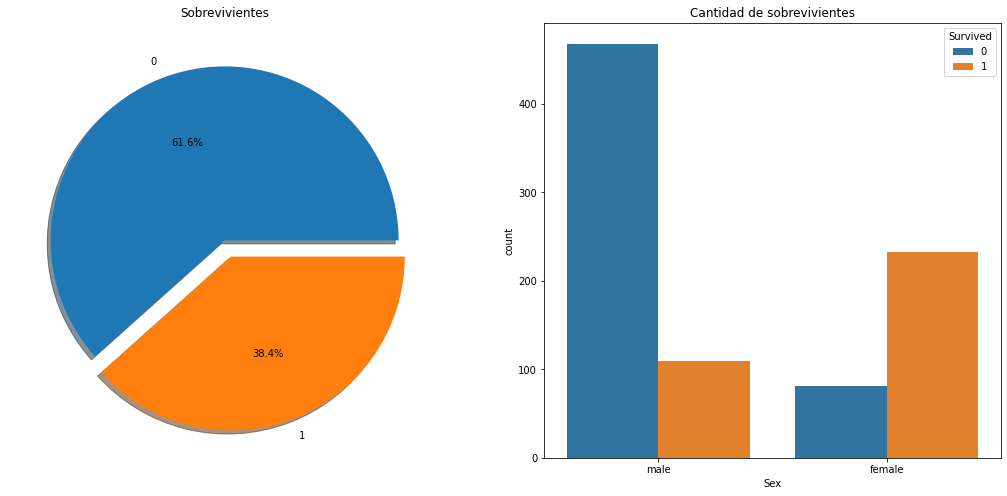

In [145]:
# Creamos 2 gráficos con la variable f y ax
# subplots En 1 fila creamos 2 Gráficos de distinto tamaño
# figsize 18 x 8 casillas
f, ax = plt.subplots(1,2,figsize = (18,8))

# Nos muestra los registros por personas que fallecieron y personas que sobrevivieron
# data['Survived'].value_counts()

# Generamos un gráfico de torta
# autoptc define el formato como se presentan los datos, definimos un número a la derecha del punto, de tipo float y en %
# ax indica la posición dónde quiero que se presente el gráfico, 0 indica el primero
# Podemos personalizar el gráfico con explode agregando una separación
data['Survived'].value_counts().plot.pie(autopct = '%1.1f%%' , ax = ax[0], explode = [0, 0.1], shadow = True)

# Cambiamos el título del gráfico
ax[0].set_title('Sobrevivientes')
ax[0].set_ylabel('')


# Creamos un segundo gráfico
# indicamos el eje x
# hue indicamos por que dato queremos agrupar
# data indicamos el dataframe que usaremos
# ax indicamos el gráfico para presentarlo
sns.countplot('Sex',hue='Survived', data = data, ax = ax[1])
ax[1].set_title('Cantidad de sobrevivientes')

# Análisis de características
#### Variables categoricas / nominales
#### Variables ordinales (Números)
#### Variables continuas (Números ) (Poseen un rango)

# Análizando variable sexo categórica

In [146]:
# Sber la cantidad de pasajeros
data['PassengerId'].count()

891

In [147]:
# Representa la cantidad de pasajeros que fallecieron o sobrevivieron
data['Survived'].value_counts()

0    549
1    342
Name: Survived, dtype: int64

In [148]:
# Agrupamos todos los datos por sexo y cantidad de sobrevivientes
# indicamos una cabecera para distribuir los elementos como quiera y mostramos las cantidades
data.groupby(['Sex','Survived'])['Survived'].count()

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: Survived, dtype: int64

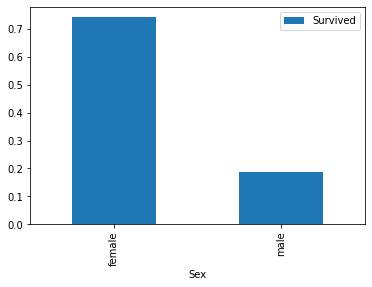

In [149]:
# Gráfico que muestre el promedio de mujeres y hombres que sobrevivieron
data[['Sex','Survived']].groupby(['Sex']).mean().plot.bar()
# Quitar la nota del gráfico
plt.show()

# Análizando variable ordinal PClass

In [150]:
# Gráfico cruzado y de claor
pd.crosstab(data['Pclass'], data['Survived'], margins = True).style.background_gradient(cmap = 'summer_r')


Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


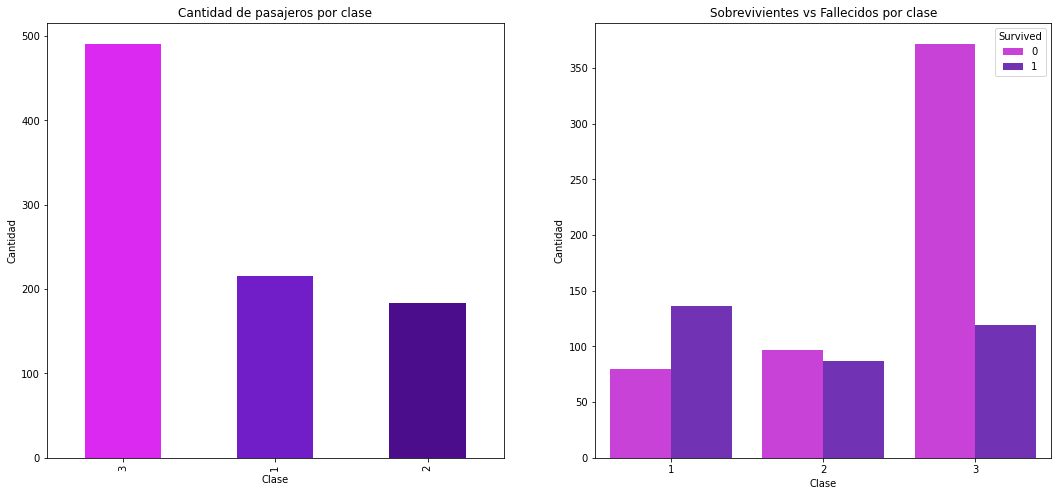

In [151]:
#
f, ax = plt.subplots(1,2, figsize = (18,8))
data['Pclass'].value_counts().plot.bar(ax = ax[0], color = ['#DC29F1','#711DC8','#4B0D8C'])
ax[0].set_title('Cantidad de pasajeros por clase')
ax[0].set_ylabel('Cantidad')
ax[0].set_xlabel('Clase')

sns.countplot('Pclass', hue='Survived', data = data, ax = ax[1], palette=['#DC29F1',"#711DC8"])
ax[1].set_title('Sobrevivientes vs Fallecidos por clase')
ax[1].set_ylabel('Cantidad')
ax[1].set_xlabel('Clase')
plt.show()

# Analizar la tasa de supervivencia según sexo y clase

In [152]:
pd.crosstab([data['Sex'], data['Survived']], data['Pclass'], margins = True).style.background_gradient(cmap = 'summer_r')

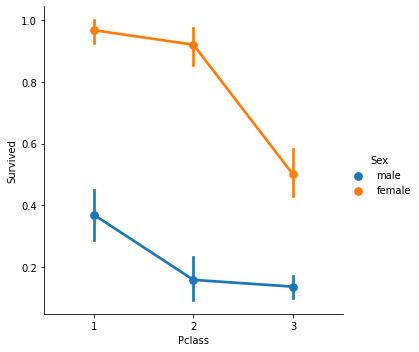

In [153]:
# Gráfico de tipo factor
sns.factorplot('Pclass','Survived', hue='Sex', data = data)
plt.show()

# Analizando el pasaje (Característica continúa)

In [154]:
print("El pasaje más caro : " , data['Fare'].max())
print("El pasaje más barato : " , data['Fare'].min())

El pasaje más caro :  512.3292
El pasaje más barato :  0.0


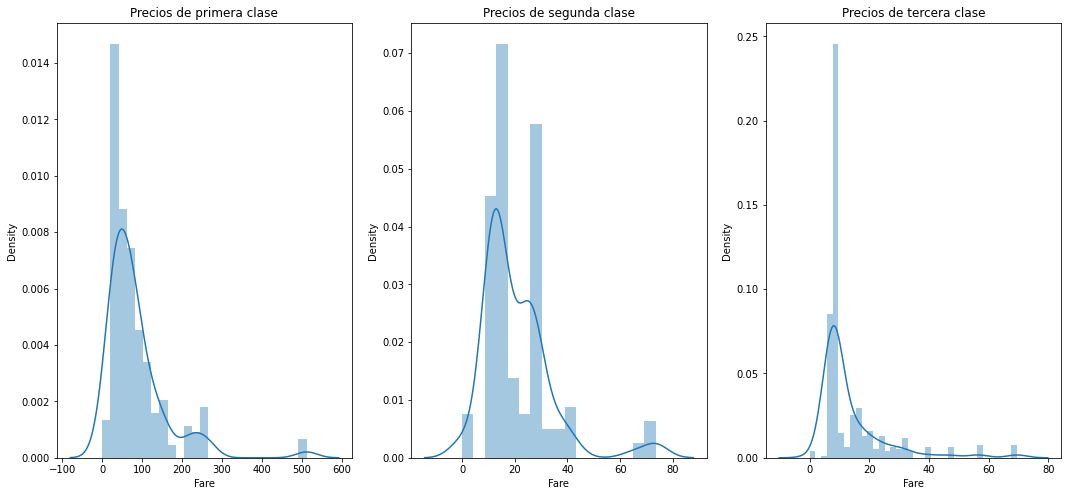

In [155]:
f, ax = plt.subplots(1,3 , figsize = (18,8))
sns.distplot(data[data['Pclass'] == 1]['Fare'], ax = ax[0])
ax[0].set_title('Precios de primera clase')

sns.distplot(data[data['Pclass'] == 2]['Fare'], ax = ax[1])
ax[1].set_title('Precios de segunda clase')

sns.distplot(data[data['Pclass'] == 3]['Fare'], ax = ax[2])
ax[2].set_title('Precios de tercera clase')

plt.show()

# Limpieza de datos
- Convertir algunas variables continuas en rangos.
- Convertir valores String en valores númericos
- Eliminar características innecesarias
- Corregir valores nulos


- **Problemas con la característica de la edad:**

In [156]:
# Establecer rangos para agrupar
# Binning o Normalizacion
data['rango_de_edad'] = 0
data.loc[data['Age'] <= 16, 'rango_de_edad'] = 0
data.loc[ (data['Age'] > 16) & (data['Age'] <= 32) , 'rango_de_edad'] = 1
data.loc[ (data['Age'] > 32) & (data['Age'] <= 48) , 'rango_de_edad'] = 2
data.loc[ (data['Age'] > 48) & (data['Age'] <= 64) , 'rango_de_edad'] = 3
data.loc[ (data['Age'] > 64) , 'rango_de_edad'] = 4

In [157]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,rango_de_edad
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,2


In [158]:
# Comprobar el número de pasajeros de cada banda
data['rango_de_edad'].value_counts().to_frame().style.background_gradient(cmap = 'summer_r')

,rango_de_edad
1,346
0,277
2,188
3,69
4,11


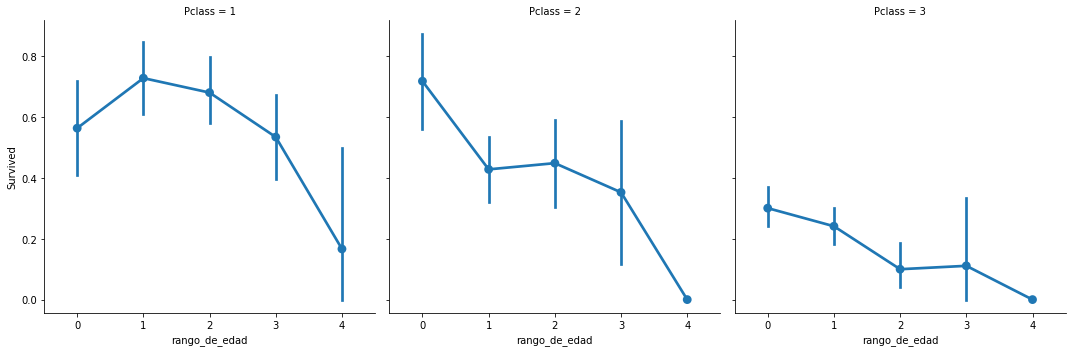

In [159]:
sns.factorplot('rango_de_edad','Survived',data = data, col = 'Pclass')

- **Problemas con la característica del pasaje**

In [160]:
data['rango_pasaje'] = pd.qcut(data['Fare'], 4)

In [161]:
data.groupby(['rango_pasaje'])['Survived'].mean().to_frame().style.background_gradient(cmap = 'summer_r')

,Survived
rango_pasaje,
"(-0.001, 7.91]",0.197309
"(7.91, 14.454]",0.303571
"(14.454, 31.0]",0.454955
"(31.0, 512.329]",0.581081


In [162]:
data['categoria_pasaje'] = 0
data.loc[data['Fare'] <= 7.91, 'categoria_pasaje'] = 0
data.loc[ (data['Fare'] > 7.91) & (data['Fare'] <= 14.454), 'categoria_pasaje'] = 1
data.loc[ (data['Fare'] > 14.454) & (data['Fare'] <= 31.0), 'categoria_pasaje'] = 2
data.loc[ (data['Fare'] > 31.0) & (data['Fare'] <= 512.329), 'categoria_pasaje'] = 3

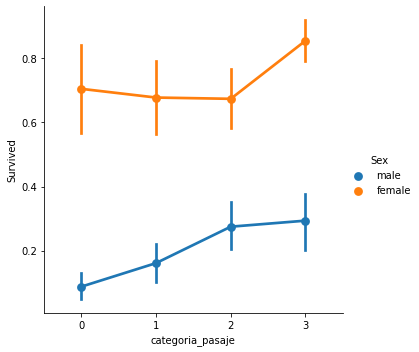

In [163]:
sns.factorplot('categoria_pasaje','Survived', data = data, hue = 'Sex')

### Limpieza de datos : Convertir valores String en valores numericos

In [164]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,rango_de_edad,rango_pasaje,categoria_pasaje
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,1,"(-0.001, 7.91]",0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,2,"(31.0, 512.329]",3
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,1,"(7.91, 14.454]",1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,2,"(31.0, 512.329]",3
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,2,"(7.91, 14.454]",1


In [165]:
data['Sex'].replace(['male','female'],[0,1], inplace = True)
data['Embarked'].replace(['S','C','Q'],[0,1,2], inplace = True)

In [166]:
data.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,rango_de_edad,rango_pasaje,categoria_pasaje
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,NaN,0.0,1,"(-0.001, 7.91]",0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C85,1.0,2,"(31.0, 512.329]",3
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,NaN,0.0,1,"(7.91, 14.454]",1


### Eliminar características innecesarias del modelo
- PassengerId -> No se puede clasificar.
- Nombre -> No necesitamos el nombre, ya que no se puede convertir en ningún valor categórico.
- Edad -> Tenemos la columna rango de edad, porlo que o es necesario
- Ticket -> Es una cadena aleatoria que no se puede clasificar
- Pasaje -> Muchos valores de NaN y también muchos pasajeros tienen varias cabinas, esta es una característica inútil
- Rango_pasaje -> Tenemos la columna categoría_pasaje

In [167]:
data.drop(['PassengerId','Name','Age','Ticket','Fare','Cabin','rango_pasaje'], axis = 1 , inplace = True)

In [168]:
data.head(3)

,Survived,Pclass,Sex,SibSp,Parch,Embarked,rango_de_edad,categoria_pasaje
0,0,3,0,1,0,0.0,1,0
1,1,1,1,1,0,1.0,2,3
2,1,3,1,0,0,0.0,1,1


## Tratamiento de datos nulos
- Podemos eliminarlos
- Podemos dejarlos como están
- Podemos deducirlos

In [169]:
data.isnull().sum()

Survived            0
Pclass              0
Sex                 0
SibSp               0
Parch               0
Embarked            2
rango_de_edad       0
categoria_pasaje    0
dtype: int64

In [170]:
# Debido a que son pocos los registros nulos intentaremos deducir su puerta de embarque
data[data['Embarked'].isnull()]

,Survived,Pclass,Sex,SibSp,Parch,Embarked,rango_de_edad,categoria_pasaje
61,1,1,1,0,0,NaN,2,3
829,1,1,1,0,0,NaN,3,3


Text(0.5, 1.0, 'Número de pasajeros que abordaron')

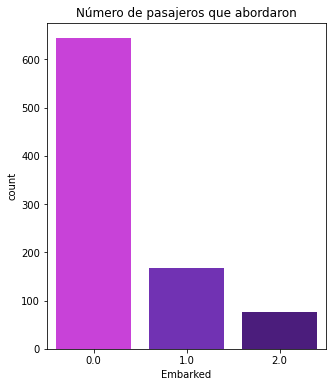

In [171]:
f, ax = plt.subplots(1,1,figsize = (5,6))
sns.countplot('Embarked', data = data, ax = ax, palette = ['#DC29F1','#711DC8','#4B0D8C'])
ax.set_title('Número de pasajeros que abordaron')

In [172]:
# Deducimos que la puerta de embarque que tomaron fue la 0, porque es la mayor cantidad de registros
data['Embarked'].fillna(0, inplace = True)

In [173]:
# Verificamos no existen datos nulos en el dataframe
data.isnull().sum()

Survived            0
Pclass              0
Sex                 0
SibSp               0
Parch               0
Embarked            0
rango_de_edad       0
categoria_pasaje    0
dtype: int64

In [174]:
# Exportamos nuestro archivo a csv
data.to_csv('Cleaning_titanic.csv')

In [175]:
# Exportamos nuestro archivo a excel
data.to_excel('Cleaning_titanic.xlsx')